# Alpha Estimation: Implicit Crank--Nicolson Grid-Resolution Comparison

This notebook estimates soil thermal diffusivity using only the refined implicit method in `soil_inverse`.

The final plot compares two vertical grid resolutions:

- `dz = 0.05 m`, equivalent to `cells_per_gap = 5`
- `dz = 0.01 m`, equivalent to `cells_per_gap = 25`

The time integration is fixed at `theta = 0.5`, i.e. the Crank--Nicolson method.


In [1]:
from pathlib import Path
import math
import string

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.ticker import MultipleLocator
import matplotlib.ticker as ticker
import matplotlib.dates as mdates

from soil_inverse import (
    HeatGrid,
    TikhonovRegularization,
    load_and_resample_soil_csv,
    median_time_step_seconds,
    make_window_indices,
    solve_adjoint_gradient_descent,
)

CSV_PATH = Path("Lupit_20210729_0812.csv")
OUTPUT_DIR = Path("00_output_figures/01_alpha_estimation")
OUTPUT_DIR.mkdir(exist_ok=True)

TEMP_COLUMNS = ["T1", "T2", "T3", "T4"]
WATER_CONTENT_COLUMNS = ["M1", "M2", "M3", "M4"]
DEPTHS_M = np.array([0.25, 0.50, 0.75, 1.00], dtype=float)

INVERSE_START = pd.Timestamp("2021-07-29 12:00")
INVERSE_END = pd.Timestamp("2021-08-12 00:00")
WINDOW_HOURS = 3.0
WINDOW_STRIDE_HOURS = 1.0
ALPHA_INITIAL = 1.0e-6
ALPHA_BOUNDS = (1.0e-8, 1.0e-5)
WINDOW_TIKHONOV = TikhonovRegularization(beta=1.0e12, prior=1.0e-6)

# Implicit Crank--Nicolson grids to compare.
GRID_DZ_VALUES = (0.05, 0.01)
THETA_CN = 0.5
MAX_WINDOWS = None  # set an integer for quick tests

FIG_PATH = OUTPUT_DIR / "alpha_estimation_implicit_grid_comparison.jpg"
CSV_PATH_OUT = OUTPUT_DIR / "alpha_estimation_implicit_grid_comparison.csv"
SUMMARY_CSV_PATH = OUTPUT_DIR / "alpha_estimation_implicit_grid_comparison_summary.csv"

plt.rcParams["text.usetex"] = False
plt.rcParams["mathtext.fontset"] = "cm"
plt.rcParams["font.family"] = "Times New Roman"

alphabet = list(string.ascii_lowercase)


## 1. Data and Sliding Windows

The analysis period and windowing follow the original `alpha_estimation.jpg` workflow: 3-hour windows with 1-hour stride over the full selected period.


In [2]:
times_all, obs_all_full, soil_water_content_all_full, resampled_data = load_and_resample_soil_csv(
    CSV_PATH,
    TEMP_COLUMNS,
    WATER_CONTENT_COLUMNS,
    resample_interval="10min",
)

time_mask = np.array([(INVERSE_START <= pd.Timestamp(t) <= INVERSE_END) for t in times_all], dtype=bool)
if not time_mask.any():
    raise ValueError(f"No data inside inverse period: {INVERSE_START} -> {INVERSE_END}")

times = times_all[time_mask]
obs_all = obs_all_full[time_mask]
soil_water_content_all = soil_water_content_all_full[time_mask]

dt_seconds = median_time_step_seconds(times)
windows_all = make_window_indices(times, WINDOW_HOURS, WINDOW_STRIDE_HOURS, min_points=4)
windows = windows_all if MAX_WINDOWS is None else windows_all[:MAX_WINDOWS]

print(f"data interval = {times[0]} -> {times[-1]}")
print(f"rows = {len(times)}")
print(f"windows = {len(windows)}")
print(f"dt = {dt_seconds:.0f} sec")


data interval = 2021-07-29 12:00:00 -> 2021-08-11 23:50:00
rows = 1944
windows = 321
dt = 600 sec


## 2. Build Implicit Crank--Nicolson Grids

The refined implicit solver uses the sensor depths as Dirichlet/data locations but solves the 1-D heat equation on a denser vertical grid. For uniformly spaced sensors, `cells_per_gap = sensor_gap / dz`.


In [3]:
def cells_per_gap_from_dz(depths_m, dz_m):
    diffs = np.diff(np.asarray(depths_m, dtype=float))
    if not np.allclose(diffs, diffs[0]):
        raise ValueError("This helper expects uniformly spaced sensor depths.")
    cells_per_gap_float = diffs[0] / float(dz_m)
    cells_per_gap = int(round(cells_per_gap_float))
    if not np.isclose(cells_per_gap_float, cells_per_gap):
        raise ValueError(f"dz={dz_m} does not evenly divide sensor gap={diffs[0]}")
    return cells_per_gap


grid_configs = []
for dz_m in GRID_DZ_VALUES:
    cells_per_gap = cells_per_gap_from_dz(DEPTHS_M, dz_m)
    grid = HeatGrid(
        DEPTHS_M,
        dt_seconds=dt_seconds,
        cells_per_gap=cells_per_gap,
        theta=THETA_CN,
    )
    grid_configs.append({
        "dz_m": float(dz_m),
        "cells_per_gap": int(cells_per_gap),
        "grid": grid,
    })
    print(
        f"dz={dz_m:.3f} m -> cells_per_gap={cells_per_gap}, "
        f"n_cells={grid.n_cells}, n_nodes={grid.n_cells + 1}, theta={grid.theta}, "
        f"r(alpha=1e-6)={grid.r(1.0e-6):.6f}"
    )


dz=0.050 m -> cells_per_gap=5, n_cells=15, n_nodes=16, theta=0.5, r(alpha=1e-6)=0.240000
dz=0.010 m -> cells_per_gap=25, n_cells=75, n_nodes=76, theta=0.5, r(alpha=1e-6)=6.000000


## 3. Run Windowed Alpha Estimation

For each window and grid resolution, alpha is estimated with the implicit Crank--Nicolson solver.

Two objective variants are retained from the original figure logic:

- L2 objective
- L2 + Tikhonov regularization


In [4]:
def solve_implicit_window(obs_window, grid, reg=None):
    return solve_adjoint_gradient_descent(
        obs_window,
        grid,
        alpha_initial=ALPHA_INITIAL,
        bounds=ALPHA_BOUNDS,
        reg=reg,
        space_scheme="central",
    )


def run_grid_comparison(windows):
    rows = []
    for k, idx in enumerate(windows):
        obs_w = obs_all[idx]
        if np.isnan(obs_w).any():
            continue
        center_position = len(idx) // 2
        center_index = int(idx[center_position])

        for cfg in grid_configs:
            dz_m = cfg["dz_m"]
            cells_per_gap = cfg["cells_per_gap"]
            grid = cfg["grid"]
            solved = {
                "l2": solve_implicit_window(obs_w, grid, reg=None),
                "tikhonov": solve_implicit_window(obs_w, grid, reg=WINDOW_TIKHONOV),
            }
            for objective_type, result in solved.items():
                method = f"implicit_dz{dz_m:.2f}_{objective_type}".replace(".", "p")
                rows.append({
                    "window": k,
                    "method": method,
                    "objective_type": objective_type,
                    "dz_m": dz_m,
                    "cells_per_gap": cells_per_gap,
                    "n_cells": grid.n_cells,
                    "n_nodes": grid.n_cells + 1,
                    "theta": grid.theta,
                    "start": times[idx[0]],
                    "center": times[center_index],
                    "end": times[idx[-1]],
                    "alpha": result["alpha"],
                    "cost": result["cost"],
                    "nit": result["nit"],
                    "nfev": result.get("nfev", np.nan),
                    "success": result.get("success", True),
                    "M1": soil_water_content_all[center_index, 0],
                    "M2": soil_water_content_all[center_index, 1],
                    "M3": soil_water_content_all[center_index, 2],
                    "M4": soil_water_content_all[center_index, 3],
                    "mean_M": float(np.nanmean(soil_water_content_all[center_index])),
                    "window_mean_M": float(np.nanmean(soil_water_content_all[idx])),
                })
        if (k + 1) % 50 == 0:
            print(f"solved windows = {k + 1}/{len(windows)}")
    return pd.DataFrame(rows)

comparison_df = run_grid_comparison(windows)
comparison_df.to_csv(CSV_PATH_OUT, index=False)

summary_df = (
    comparison_df
    .groupby(["method", "objective_type", "dz_m", "cells_per_gap", "n_cells", "n_nodes", "theta"])
    .agg(
        n_windows=("alpha", "count"),
        mean_alpha=("alpha", "mean"),
        median_alpha=("alpha", "median"),
        std_alpha=("alpha", "std"),
        mean_cost=("cost", "mean"),
        median_cost=("cost", "median"),
        mean_nit=("nit", "mean"),
        median_nit=("nit", "median"),
    )
    .reset_index()
)
summary_df.to_csv(SUMMARY_CSV_PATH, index=False)

print(summary_df.to_string(index=False))
print("saved:", CSV_PATH_OUT)
print("saved:", SUMMARY_CSV_PATH)


solved windows = 50/321
solved windows = 100/321
solved windows = 150/321
solved windows = 200/321
solved windows = 250/321
solved windows = 300/321
                  method objective_type  dz_m  cells_per_gap  n_cells  n_nodes  theta  n_windows   mean_alpha  median_alpha    std_alpha  mean_cost  median_cost  mean_nit  median_nit
      implicit_dz0p01_l2             l2  0.01             25       75       76    0.5        321 3.339064e-07  2.137052e-07 3.678861e-07   0.067571     0.040376  4.551402           5
implicit_dz0p01_tikhonov       tikhonov  0.01             25       75       76    0.5        321 6.344823e-07  6.229814e-07 2.523850e-07   0.242092     0.238860  4.931464           5
      implicit_dz0p05_l2             l2  0.05              5       15       16    0.5        321 3.778014e-07  2.699452e-07 3.557973e-07   0.058928     0.036291  4.520249           5
implicit_dz0p05_tikhonov       tikhonov  0.05              5       15       16    0.5        321 6.568784e-07  6.413942

## 4. Plot Grid-Resolution Comparison

The final figure uses only the implicit Crank--Nicolson method (`theta = 0.5`) and compares `dz = 0.05 m` against `dz = 0.01 m`.


NameError: name 'ax_iter' is not defined

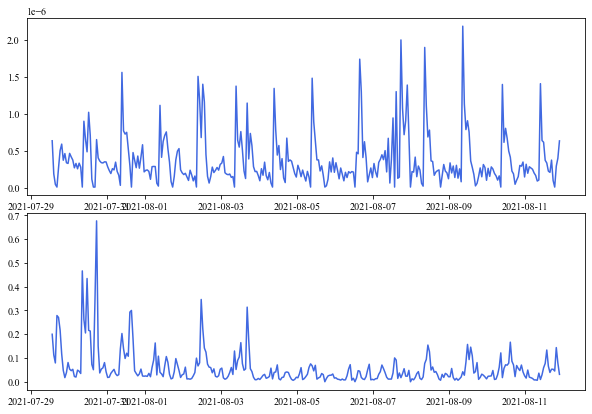

In [5]:
Color = {
    "implicit_dz0p05_l2": "royalblue",
    "implicit_dz0p05_tikhonov": "tomato",
#     "implicit_dz0p01_l2": "green",
#     "implicit_dz0p01_tikhonov": "black",
}
Label = {
    "implicit_dz0p05_l2": r"Implicit Crank-Nicolson method, $dz=0.05$ m (L2)",
    "implicit_dz0p05_tikhonov": r"Implicit Crank-Nicolson method, $dz=0.05$ m (L2 + Tikhonov)",
#     "implicit_dz0p01_l2": r"Implicit Crank-Nicolson method, $dz=0.01$ m (L2)",
#     "implicit_dz0p01_tikhonov": r"Implicit Crank-Nicolson method, $dz=0.01$ m (L2 + Tikhonov)",
}
plot_order = [
    "implicit_dz0p05_l2",
    "implicit_dz0p05_tikhonov",
#     "implicit_dz0p01_l2",
#     "implicit_dz0p01_tikhonov",
]


def text_alphabet(handel, w, xx=0.05, yy=0.98):
    handel.text(
        xx,
        yy,
        "({})".format(w),
        transform=handel.transAxes,
        ha="left",
        va="top",
        fontsize=18,
        bbox=dict(facecolor="white", alpha=0.5, edgecolor="none"),
    )


def plot_method_series(ax, df, method, key, label=None, color=None, linestyle="-"):
    subset = df[df["method"] == method].copy()
    subset["center"] = pd.to_datetime(subset["center"])
    subset = subset.sort_values("center")
    ax.plot(
        subset["center"],
        subset[key].astype(float),
        color=color or Color[method],
        linewidth=1.5,
        linestyle=linestyle,
        label=label or Label[method],
    )

fig = plt.figure(figsize=[10, 14])
plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=None, hspace=0.1)
spec = gridspec.GridSpec(ncols=1, nrows=4, height_ratios=[1, 1, 1, 1])

axxList = []
ax_alpha = fig.add_subplot(spec[0, 0])
axxList.append(ax_alpha)
ax_cost = fig.add_subplot(spec[1, 0], sharex=ax_alpha)
axxList.append(ax_cost)
# ax_iter = fig.add_subplot(spec[2, 0], sharex=ax_alpha)
# axxList.append(ax_iter)

for method in plot_order:
    avg = summary_df.loc[summary_df["method"] == method, "mean_alpha"].iloc[0]
    label = Label[method] + r"; $\alpha_{\rm avg}=$" + f"{avg:.2e} m$^2$/s"
    plot_method_series(ax_alpha, comparison_df, method, "alpha", label=label)
    plot_method_series(ax_cost, comparison_df, method, "cost")
    plot_method_series(ax_iter, comparison_df, method, "nit")

ax_alpha.set_yscale("log")
ax_alpha.set_ylim(5e-9, 1e-5)
ax_alpha.set_ylabel("Soil thermal diffusivity\n" + r"$\alpha\,\,$[m$^2$/s]", fontsize=18)
ax_alpha.legend(
    bbox_to_anchor=(0.24, 1.14, 0.70, 0.2),
    loc="center",
    fontsize=12,
    labelspacing=0.35,
    facecolor="white",
    labelcolor="black",
    ncol=1,
)

ax_cost.set_yscale("log")
ax_cost.set_ylabel("Cost function value", fontsize=18)

ax_cost.set_xlabel("Window center time", fontsize=18)

positive_cost = comparison_df.loc[comparison_df["cost"] > 0, "cost"].astype(float)
if len(positive_cost):
    ax_cost.set_ylim(max(1e-8, positive_cost.min() * 0.5), positive_cost.max() * 2.0)
ax_cost.set_ylim(5e-5, 1e1)




# ax_iter.set_xlabel("Window center time", fontsize=18)
# ax_iter.set_ylabel("Iterations", fontsize=18)
# ax_iter.yaxis.set_major_locator(MultipleLocator(5))
# ax_iter.yaxis.set_minor_locator(MultipleLocator(2.5))
# ax_iter.set_ylim(0, max(10, float(comparison_df["nit"].max()) + 2))

hours_major = mdates.HourLocator(byhour=[0])
hours_minor = mdates.HourLocator(byhour=[12])
ax_cost.xaxis.set_major_locator(hours_major)
ax_cost.xaxis.set_minor_locator(hours_minor)
ax_cost.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))
ax_cost.set_xlim(pd.Timestamp(INVERSE_START), pd.Timestamp(INVERSE_END))
plt.setp(ax_cost.get_xticklabels(), rotation=30, ha="right")

for jj, axx in enumerate(axxList):
    text_alphabet(axx, alphabet[jj], xx=0.02, yy=0.93)
    axx.tick_params(axis="both", labelsize=16)
    axx.grid(True, which="major", color="gray", alpha=0.6, linewidth=0.8)
    axx.grid(True, which="minor", color="lightgray", alpha=0.5, linewidth=0.4, linestyle="--")

for axx in axxList[:1]:
    axx.set_xlabel("")
    axx.tick_params(axis="x", which="both", labelbottom=False)

for ax in [ax_alpha, ax_cost]:
    ax.yaxis.set_major_locator(ticker.LogLocator(base=10.0))
    ax.yaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=100))
    ax.yaxis.set_minor_formatter(ticker.NullFormatter())

fig.savefig(FIG_PATH, dpi=800, bbox_inches="tight")
plt.show()
print("saved figure:", FIG_PATH)


## 5. Typhoon Event Tikhonov-Regularized Alpha Comparison

This figure focuses on the typhoon-event interval from 2021-08-06 00:00 to 2021-08-09 00:00. Only the L2 objective function with Tikhonov regularization is retained, and the two implicit Crank--Nicolson grid resolutions, `dz = 0.05 m` and `dz = 0.01 m`, are compared.

In [ ]:
EVENT_START = pd.Timestamp("2021-08-06 00:00")
EVENT_END = pd.Timestamp("2021-08-09 00:00")
EVENT_FIG_PATH = OUTPUT_DIR / "inverse_methods_typhoon_event.jpg"
EVENT_CSV_PATH = OUTPUT_DIR / "inverse_methods_typhoon_event.csv"

# Select the event-period sliding windows by window-center time.
event_comparison_df = comparison_df.copy()
for col in ["start", "center", "end"]:
    event_comparison_df[col] = pd.to_datetime(event_comparison_df[col])
event_comparison_df = event_comparison_df[
    (event_comparison_df["center"] >= EVENT_START)
    & (event_comparison_df["center"] <= EVENT_END)
].copy()

# Keep only the L2 objective function with Tikhonov regularization.
event_plot_order = [
    "implicit_dz0p05_tikhonov",
    "implicit_dz0p01_tikhonov",
]
event_comparison_df = event_comparison_df[
    event_comparison_df["method"].isin(event_plot_order)
].copy()

if event_comparison_df.empty:
    raise ValueError(f"No Tikhonov-regularized inverse-estimation windows inside event period: {EVENT_START} -> {EVENT_END}")

event_comparison_df.to_csv(EVENT_CSV_PATH, index=False)

obs_event_mask = np.array([(EVENT_START <= pd.Timestamp(t) <= EVENT_END) for t in times], dtype=bool)
if not obs_event_mask.any():
    raise ValueError(f"No observation data inside event period: {EVENT_START} -> {EVENT_END}")

obs_event_times = pd.to_datetime(times[obs_event_mask])
obs_event_values = obs_all[obs_event_mask]

EventLabel = {
    "implicit_dz0p05_tikhonov": r"$dz=0.05$ m (L2 + Tikhonov)",
    "implicit_dz0p01_tikhonov": r"$dz=0.01$ m (L2 + Tikhonov)",
}
EventColor = {
    "implicit_dz0p05_tikhonov": "tomato",
    "implicit_dz0p01_tikhonov": "black",
}

# Plot diagram: two panels only, with cost function value removed.
fig_event = plt.figure(figsize=[10, 14])
plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=None, hspace=0.1)
spec_event = gridspec.GridSpec(ncols=1, nrows=4, height_ratios=[1, 1, 1, 1])

ax_obs = fig_event.add_subplot(spec_event[0, 0])
ax_alpha = fig_event.add_subplot(spec_event[1, 0], sharex=ax_obs)
axx_event = [ax_obs, ax_alpha]

soil_temp_colors = ["royalblue", "brown", "green", "tomato"]
for j, (column, color) in enumerate(zip(TEMP_COLUMNS, soil_temp_colors)):
    ax_obs.plot(
        obs_event_times,
        obs_event_values[:, j],
        color=color,
        linewidth=1.6,
        label=f"{DEPTHS_M[j]:.2f} m",
    )

ax_obs.set_ylabel("In-situ temperature\n" + r"$T\,\,[^{\circ}\mathrm{C}]$", fontsize=18)
ax_obs.legend(
    title="Dazhou SMS",
    loc="upper left",
    bbox_to_anchor=(0.06, 0.99),
    fontsize=14,
    title_fontsize=14,
    labelspacing=0.35,
    scatterpoints=1,
    facecolor="white",
    labelcolor="black",
    ncol=2,
)

for method in event_plot_order:
    subset = event_comparison_df[event_comparison_df["method"] == method].copy()
    subset = subset.sort_values("center")
    if subset.empty:
        continue
    avg_alpha = float(subset["alpha"].mean())
    label = EventLabel[method] + r"; $\alpha_{\rm avg}=$" + f"{avg_alpha:.2e}" + " m$^2$/s"
    
    if method == event_plot_order[1]:
        ax_alpha.plot(
            subset["center"],
            subset["alpha"].astype(float),
            color=EventColor[method],
            linewidth=1.8,
            label=label,
            linestyle = "--",
        )
    else:
        ax_alpha.plot(
            subset["center"],
            subset["alpha"].astype(float),
            color=EventColor[method],
            linewidth=1.8,
            label=label,
            linestyle = "-",
        )        

ax_alpha.set_yscale("log")
ax_alpha.set_ylim(5e-9, 1e-5)
ax_alpha.set_ylabel("Soil thermal diffusivity\n" + r"$\alpha\,\,$[m$^2$/s]", fontsize=18)
ax_alpha.set_xlabel("Window center time", fontsize=18)
ax_alpha.legend(
    loc="upper left",
    bbox_to_anchor=(0.06, 0.99),
    fontsize=14,
    facecolor="white",
    labelcolor="black",
    labelspacing=0.35,
    ncol=1,
)

for panel_label, axx in zip(alphabet, axx_event):
    text_alphabet(axx, panel_label, xx=0.02, yy=0.93)
    axx.tick_params(axis="both", labelsize=16)
    axx.grid(True, which="major", color="gray", alpha=0.6, linewidth=0.8)
    axx.grid(True, which="minor", color="lightgray", alpha=0.5, linewidth=0.4, linestyle="--")

ax_obs.tick_params(axis="x", which="both", labelbottom=False)
ax_alpha.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
ax_alpha.xaxis.set_minor_locator(mdates.HourLocator(interval=3))
ax_alpha.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d\n%H:%M"))
ax_alpha.set_xlim(EVENT_START, EVENT_END)
ax_alpha.set_ylim(1e-8, 1e-4)
plt.setp(ax_alpha.get_xticklabels(), rotation=30, ha="right")

ax_alpha.yaxis.set_major_locator(ticker.LogLocator(base=10.0))
ax_alpha.yaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=100))
ax_alpha.yaxis.set_minor_formatter(ticker.NullFormatter())

fig_event.savefig(EVENT_FIG_PATH, dpi=800, bbox_inches="tight")
plt.show()
print("event windows =", event_comparison_df["window"].nunique())
print("saved figure:", EVENT_FIG_PATH)
print("saved data:", EVENT_CSV_PATH)
